# Riverlane's Deltakit

**What it is.** Riverlane's Python toolkit for QEC experiments: build codes and circuits, add realistic noise,
decode, analyse. Installed with pip (`pip install deltakit==0.10.2`); no repo to clone.
- Docs: https://deltakit-docs.riverlane.com · Decoding guide: https://deltakit-docs.riverlane.com/en/latest/guide/decoding.html

**The catch.** The circuit and noise tools run locally. Of the decoders, only PyMatching runs locally;
the qLDPC decoders (BP-OSD, Ambiguity Clustering) and Riverlane's own decoders run on **Riverlane's cloud**
and need an account token. Step 7 shows what that means inside the code.

| Step | What we do | Graph |
|---|---|---|
| 1 | Connect with a Deltakit token | – |
| 2 | What is inside the package | – |
| 3 | Build a surface code with Deltakit and look inside the circuit | patch picture, circuit drawing |
| 4 | Deltakit's noise models: where each one puts errors | noise counts |
| 5 | Run locally: surface code with Deltakit's PyMatching | error rate vs noise |
| 6 | The gross code in Deltakit, against stabilizer-qec and IBM's circuit | check matrix, operation counts |
| 7 | Inside the decoders: what happens when one is called | – |
| 8 | Cloud run: every Deltakit decoder on the same surface code shots | failures and time per decoder |
| 9 | Gross code: Deltakit's circuit vs IBM's, and cloud BP-OSD / AC vs our local BP-OSD | failures per decoder |
| 10 | What we take from Deltakit | – |


## Setup

Run once in a fresh environment (Python 3.12 recommended). The versions are the ones the results were produced with.

In [15]:
%pip install -q deltakit==0.10.2 stim==1.16.0 sinter==1.15.0 stabilizer-qec==2.1.0 "numpy>=2.0,<2.3" pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


### Code and data used from this folder

Functions that several notebooks share are kept in `helpers/` rather than repeated in every notebook; they are
imported from there below. Each file is commented and can be read on its own.

| File | What it is for | Used here |
|---|---|---|
| `helpers/tour_helpers.py` | plotting, tables, running and caching experiments | `cached_run`, `cloud_decoder`, `count_failures`, `deltakit_client`, `dk_noisy`, `plot_gate_counts`, `savefig`, `show_head`, `wilson` |
| `helpers/circuits.py` | loads or builds each gross / surface code circuit | `ibm_gross_memory_z` |
| `helpers/ibm_filter.py` | IBM's Z-detector filter (from IBM's repo, Apache-2.0) | `ibm_filtered_z` |
| `helpers/deltakit_gross.py` | gross code built with Deltakit, with IBM's noise model | `add_uniform_circuit_noise`, `deltakit_gross_memory_z_noiseless`, `z_detectors_only` |

Folders read or written:
- `results/`: cached runs (re-used, not re-run)
- `figures/`: PNG files written by this notebook
- `cache/`: IBM-filtered circuits, written on first use

## Step 1 · Connect

The cloud decoders need a Deltakit account token (free, from https://deltakit.riverlane.com). Paste it between
the quotes or set the environment variable `DELTAKIT_TOKEN`. The token is never printed. **Never commit a
notebook with a token in it.** Without a token, the local steps run and the cloud steps show saved results.

In [ ]:
DELTAKIT_TOKEN = ""      # <-- paste a Deltakit token here (or set the DELTAKIT_TOKEN environment variable)

import sys, time; sys.path.insert(0, "helpers")   # helper functions (see "Code and data used" above)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, stim
import tour_helpers as tour
cloud = tour.deltakit_client(DELTAKIT_TOKEN)      # None if no token / no connection

Deltakit cloud client ready.


## Step 2 · What is inside the package

| Part | What it is for | Runs |
|---|---|---|
| `deltakit.circuit` | Deltakit's own circuit objects (qubits, gates, noise channels); converts to Stim | local |
| `deltakit.explorer.codes` | Code definitions and circuit builders: repetition, rotated/unrotated planar (surface), toric, general CSS, **bivariate bicycle** | local |
| `deltakit.explorer.qpu` | Noise models (`ToyNoise`, `SI1000Noise`, `SD6Noise`, phenomenological) and native gate sets | local |
| `deltakit.decode` | Decoders: `PyMatchingDecoder` locally; `MWPMDecoder`, `CCDecoder`, `BeliefMatchingDecoder`, `BPOSDecoder`, `ACDecoder`, `LCDecoder` through the cloud | local + cloud |
| `deltakit.explorer.Client` | The connection to Riverlane's server | cloud |

In [17]:
import deltakit.explorer.codes as codes, deltakit.explorer.qpu as qpu, deltakit.decode as decode
print("codes:      ", [x for x in dir(codes) if x.endswith("Code")])
print("noise models:", [x for x in dir(qpu) if x.endswith("Noise")])
print("decoders:   ", [x for x in dir(decode) if x.endswith("Decoder")])

codes:       ['BivariateBicycleCode', 'CSSCode', 'RepetitionCode', 'RotatedPlanarCode', 'StabiliserCode', 'UnrotatedPlanarCode', 'UnrotatedToricCode']
noise models: ['PhenomenologicalNoise', 'PhysicalNoise', 'SD6Noise', 'SI1000Noise', 'ToyNoise']
decoders:    ['ACDecoder', 'BPOSDecoder', 'BeliefMatchingDecoder', 'CCDecoder', 'LCDecoder', 'MWPMDecoder', 'PyMatchingDecoder']


## Step 3 · A surface code built with Deltakit

`RotatedPlanarCode(5, 5)` is the d = 5 rotated surface code. Deltakit can draw the patch: dark dots are data
qubits, orange dots are check (ancilla) qubits, the two colours of tiles are the X and Z checks.

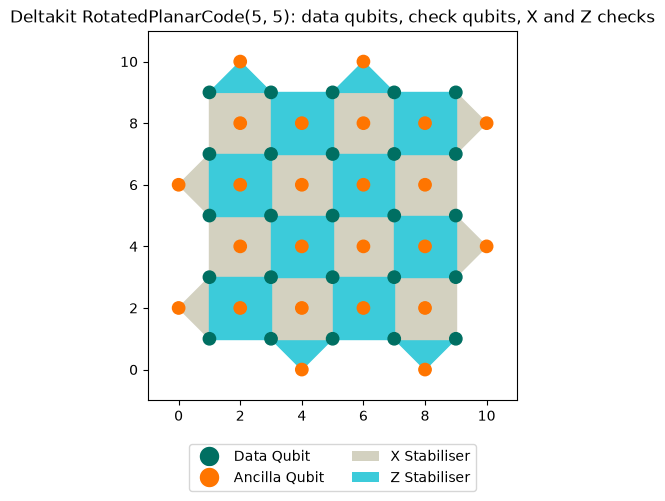

In [18]:
from deltakit.explorer.codes import RotatedPlanarCode, BivariateBicycleCode, css_code_memory_circuit
from deltakit.circuit.gates import PauliBasis

surface5 = RotatedPlanarCode(5, 5)
fig, ax = surface5.draw_patch()
ax.set_title("Deltakit RotatedPlanarCode(5, 5): data qubits, check qubits, X and Z checks")
plt.show()

`css_code_memory_circuit` turns any CSS code into a memory experiment: prepare, measure the checks for some
rounds, read out. Here d = 3 for 3 rounds, without noise yet, converted to Stim:

In [19]:
surf3 = css_code_memory_circuit(RotatedPlanarCode(3, 3), num_rounds=3, logical_basis=PauliBasis.Z)
surf3_stim = stim.Circuit(str(surf3.as_stim_circuit()))
print(f"qubits: {surf3_stim.num_qubits}   detectors: {surf3_stim.num_detectors}   observables: {surf3_stim.num_observables}")
tour.show_head(surf3_stim, 14, start="R")

qubits: 17   detectors: 24   observables: 1
... (lines 1-17 skipped)
R 16 8 2 3 9 14 4 12 11
RX 5 1 0 13 6 10 15 7
TICK
I 12 8 2 3 14 9 4 16 11
TICK
CX 5 11 0 2 13 14
CZ 1 3 10 9 7 8
TICK
CX 5 16 0 8 13 3
CZ 1 4 10 11 7 14
TICK
CX 0 9 13 16 6 8
CZ 10 14 15 2 7 12
TICK
... (99 lines in total)


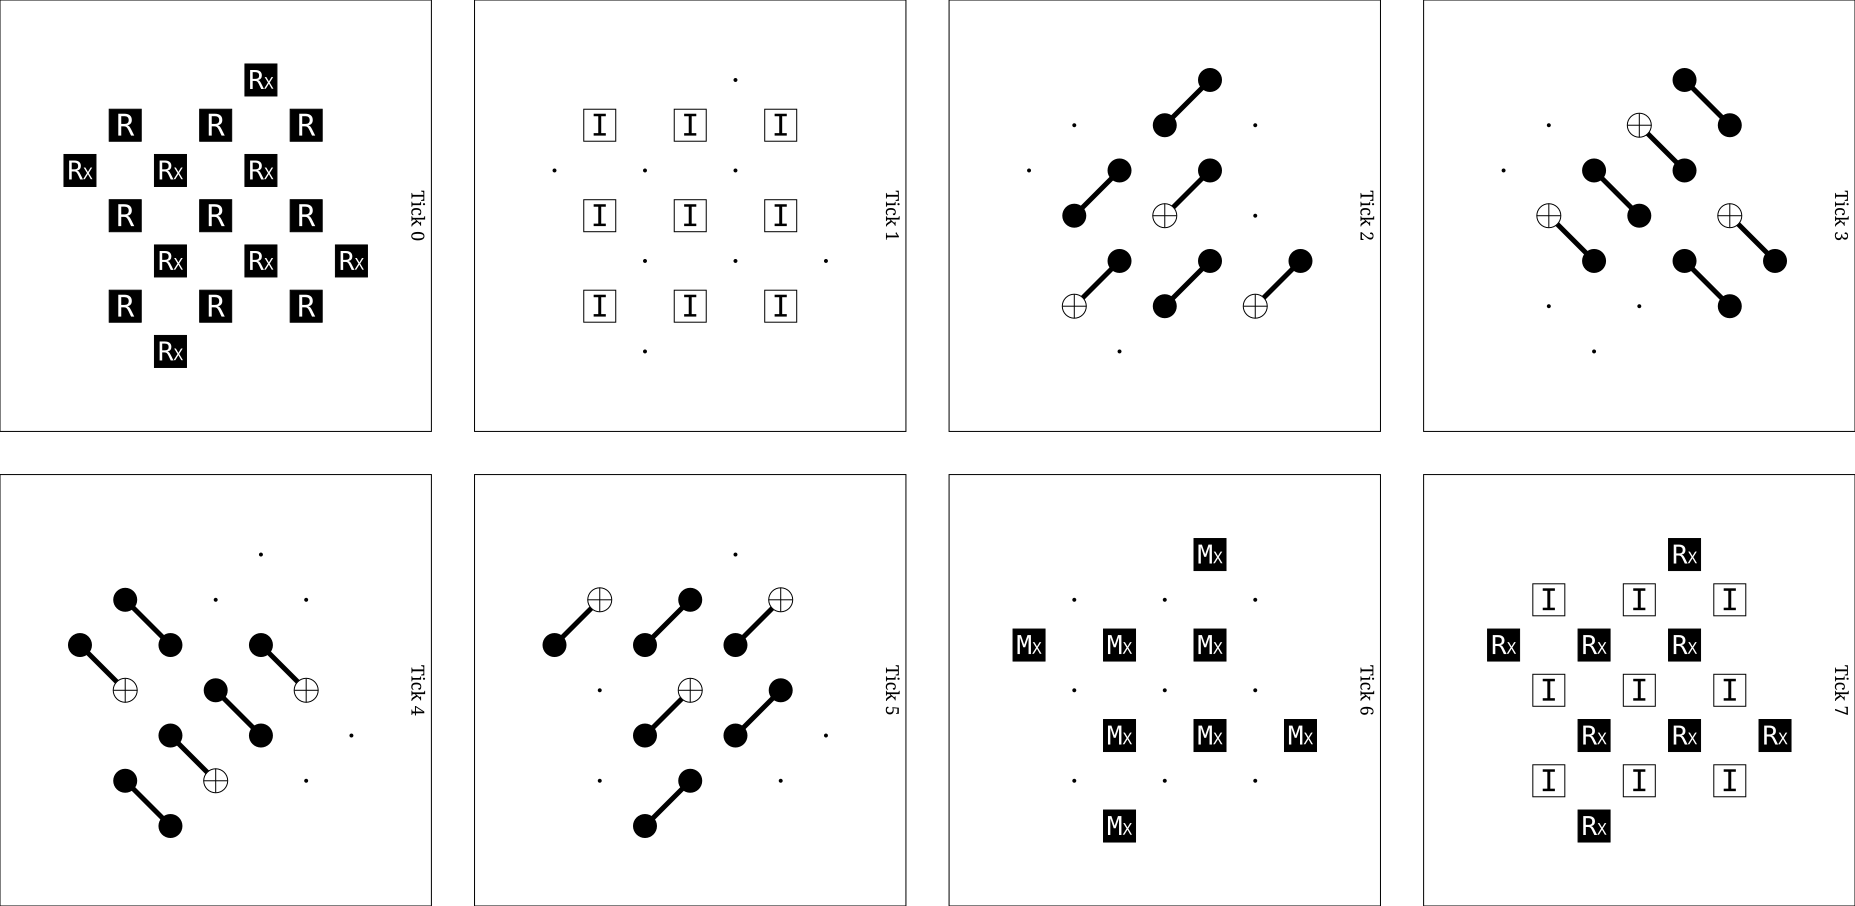

In [20]:
surf3_stim.diagram("timeslice-svg", tick=range(0, 8), rows=2)    # one round of checks, step by step

## Step 4 · Deltakit's noise models

Deltakit adds noise through a `QPU` object: the circuit is compiled to the machine's native gates and each
operation gets the noise of the chosen model. Three models at the same p = 0.005:
- **ToyNoise(p)**: two-qubit gates p, measurement flips p, single-qubit gates and idles p/10, **no reset noise**.
- **SI1000Noise(p)**: "superconducting-inspired" (Gidney, Newman, Fowler & Broughton 2021, arXiv:2108.10457): two-qubit
  gates p, measurements 5p, resets and idling during measurement 2p, single-qubit gates and other idles p/10.
- **SD6Noise(p)**: "standard depolarising": every gate, reset, measurement and idle step fails with p — the
  same idea as IBM's "uniform circuit noise".

(Values read from the noisy circuits Deltakit produces, below.)

The chart counts where each model puts noise in the d = 3 circuit.

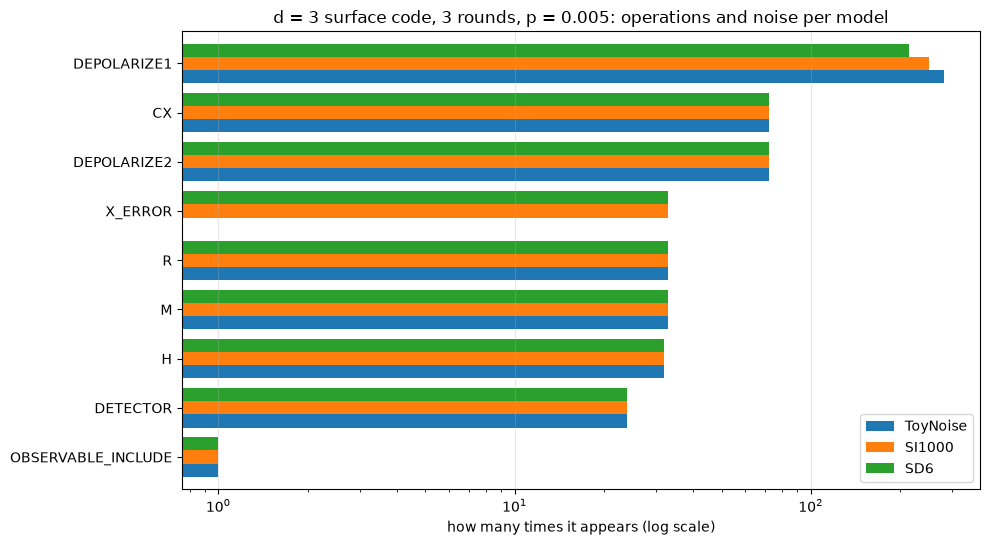

In [21]:
from deltakit.explorer.qpu import ToyNoise, SI1000Noise, SD6Noise
P = 0.005
noisy = {name: tour.dk_noisy(surf3, model(p=P))[1]
         for name, model in [("ToyNoise", ToyNoise), ("SI1000", SI1000Noise), ("SD6", SD6Noise)]}
tour.plot_gate_counts(noisy, "d = 3 surface code, 3 rounds, p = 0.005: operations and noise per model",
                      save="deltakit_noise_models.png");

## Step 5 · Run locally: surface code with Deltakit's PyMatching

Deltakit's own local decoder. `PyMatchingDecoder.construct_decoder_and_stim_circuit` builds the matching graph
from the noisy circuit and returns the circuit it will decode (Deltakit drops the X-type detectors for a Z
memory, the same simplification IBM makes); `decode_batch_to_logical_flip` returns the guess for each shot.

- **Codes:** d = 3, 5, 7 · **Noise:** SD6 (uniform), p = 0.001 to 0.008 · **Shots:** 20,000 per point (seconds).

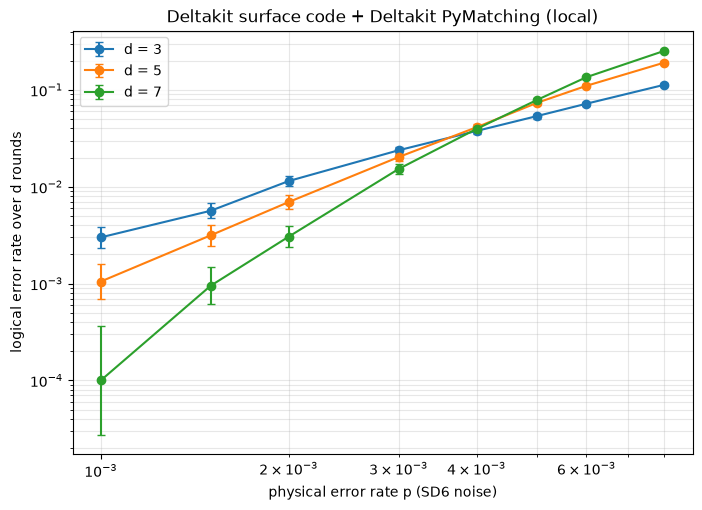

In [22]:
from deltakit.decode import PyMatchingDecoder
DISTANCES, NOISE, SHOTS = [3, 5, 7], [0.001, 0.0015, 0.002, 0.003, 0.004, 0.005, 0.006, 0.008], 20_000

rows = []
for d in DISTANCES:
    base = css_code_memory_circuit(RotatedPlanarCode(d, d), num_rounds=d, logical_basis=PauliBasis.Z)
    for p in NOISE:
        dk_c, _ = tour.dk_noisy(base, SD6Noise(p=p))
        decoder, dec_circ = PyMatchingDecoder.construct_decoder_and_stim_circuit(dk_c)   # decoder + the circuit it decodes
        st_c = stim.Circuit(str(dec_circ))      # Deltakit keeps only the Z detectors for a Z memory
        dets, obs = st_c.compile_detector_sampler(seed=d * 1000 + int(p * 1e4)).sample(SHOTS, separate_observables=True)
        f = tour.count_failures(decoder.decode_batch_to_logical_flip(dets.astype(np.uint8)), obs)
        rows.append((d, p, SHOTS, f))
surf = pd.DataFrame(rows, columns=["d", "p", "shots", "failures"])
surf["P_L"] = surf.failures / surf.shots

fig, ax = plt.subplots(figsize=(8, 5.5))
for d, r in surf.groupby("d"):
    r = r[r.failures > 0]
    lo, hi = zip(*[tour.wilson(f, n) for f, n in zip(r.failures, r.shots)])
    ax.errorbar(r.p, r.P_L, yerr=[r.P_L - np.array(lo), np.array(hi) - r.P_L], marker="o", capsize=3, label=f"d = {d}")
ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(which="both", alpha=0.3); ax.legend()
ax.set_xlabel("physical error rate p (SD6 noise)"); ax.set_ylabel("logical error rate over d rounds")
ax.set_title("Deltakit surface code + Deltakit PyMatching (local)")
tour.savefig("deltakit_surface_pymatching.png"); plt.show()

**What the graph shows.** The usual surface code picture, built and decoded entirely inside Deltakit: below
the crossing, bigger d is better; above it, worse. The crossing (threshold) is near **p ≈ 0.004**, about half
of what Stim's built-in surface code circuit gives (≈ 0.007, notebook 02). The decoder is not the reason —
plain PyMatching on the same circuit gives the same counts. The circuit is: Deltakit compiles to native gates
(extra Hadamards, 8 time steps per round) and SD6 puts noise p on **every idle qubit at every step**. At
p = 0.003 a d = 3 patch fails about 4× as often here as in Stim's circuit (446 vs 116 in 20,000 shots, our
check). Same code, same p, very different numbers: the noise model and schedule matter as much as the code.

## Step 6 · The gross code in Deltakit

Deltakit's `BivariateBicycleCode` takes the two polynomials as powers: A = x³ + y + y², B = y³ + x + x² on a
12 × 6 torus. Its check matrix H_X has 72 checks (rows) on 144 data qubits (columns), 6 ones per row.

n = 144   k = 12   H_X: (72, 144)   ones per check: {np.int64(6)}
same check matrices as stabilizer-qec: True


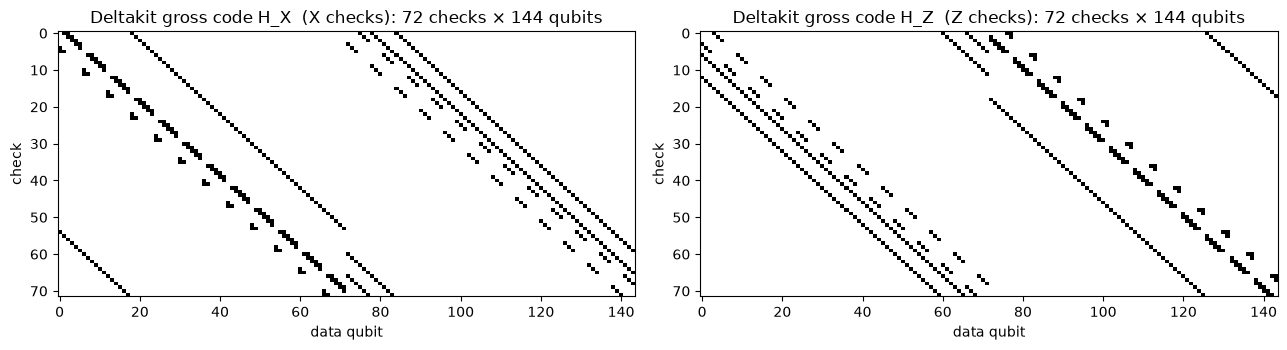

In [23]:
gross = BivariateBicycleCode(param_l=12, param_m=6, m_A_powers=[3, 1, 2], m_B_powers=[3, 1, 2])
HX, HZ = np.array(gross.m_Hx), np.array(gross.m_Hz)
print("n =", gross.n, "  k =", gross.k, "  H_X:", HX.shape, "  ones per check:", set(HX.sum(axis=1)))

import stabilizer_qec as sq                                    # pip package, used only for this check
sHX, sHZ = sq.BivariateBicycleCode("gross").check_matrices()
print("same check matrices as stabilizer-qec:", np.array_equal(HX, sHX) and np.array_equal(HZ, sHZ))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, H, t in [(axs[0], HX, "H_X  (X checks)"), (axs[1], HZ, "H_Z  (Z checks)")]:
    ax.imshow(H, cmap="Greys", aspect="auto", interpolation="nearest")
    ax.set_title(f"Deltakit gross code {t}: 72 checks × 144 qubits"); ax.set_xlabel("data qubit"); ax.set_ylabel("check")
plt.tight_layout(); tour.savefig("deltakit_gross_check_matrices.png"); plt.show()

**Same code, different circuit.** The check matrices match stabilizer-qec exactly. But Deltakit builds the
syndrome circuit with its own general CSS schedule, not the depth-8 circuit from Bravyi et al. that IBM and
stabilizer-qec use. To compare like with like we give Deltakit's circuit IBM's exact noise model
(`add_uniform_circuit_noise` in `helpers/deltakit_gross.py`) and keep only the Z detectors.

... (lines 1-300 skipped)
CX 116 159 124 167 136 86 148 96 64 106 104 146 253 18 266 30 282 45 7 225 21 241 240 4 137 181 149 195 160 109 170 118 183 126 125 169 286  ...
DEPOLARIZE2(0.004) 116 159 124 167 136 86 148 96 64 106 104 146 253 18 266 30 282 45 7 225 21 241 240 4 137 181 149 195 160 109 170 118 183  ...
CZ 33 216 47 267 229 284 245 8 256 22 270 34 62 77 76 115 85 27 95 40 105 52 16 63 233 248 247 177 259 191 273 204 168 220 178 234 59 74 72  ...
DEPOLARIZE2(0.004) 33 216 47 267 229 284 245 8 256 22 270 34 62 77 76 115 85 27 95 40 105 52 16 63 233 248 247 177 259 191 273 204 168 220 1 ...
TICK
CX 116 27 124 40 136 52 148 63 64 77 104 115 253 191 266 204 282 220 7 234 21 248 240 177 137 25 149 38 160 50 170 60 183 74 125 11 286 190  ...
DEPOLARIZE2(0.004) 116 27 124 40 136 52 148 63 64 77 104 115 253 191 266 204 282 220 7 234 21 248 240 177 137 25 149 38 160 50 170 60 183 74 ...
CZ 33 86 47 96 229 106 245 146 256 159 270 167 62 45 76 225 85 241 95 4 105 18 16 30 233 109 247 11

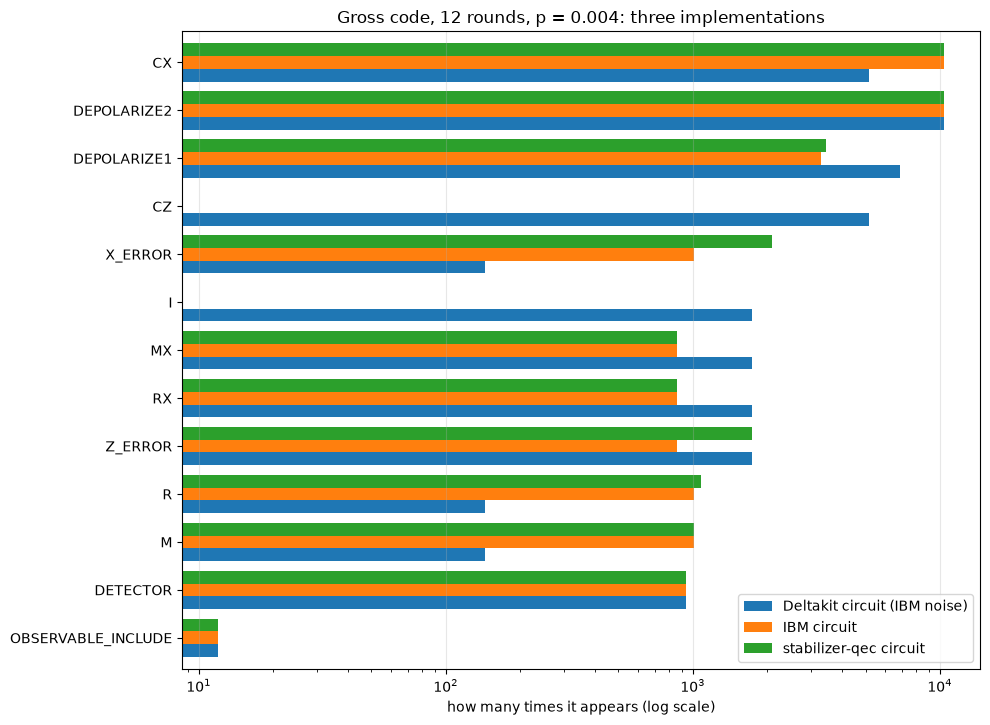

In [24]:
from deltakit_gross import deltakit_gross_memory_z_noiseless, add_uniform_circuit_noise, z_detectors_only
from circuits import ibm_gross_memory_z
from ibm_filter import ibm_filtered_z

GP = 0.004
dk_gross = z_detectors_only(add_uniform_circuit_noise(deltakit_gross_memory_z_noiseless(12), GP))
ibm_gross = ibm_filtered_z(ibm_gross_memory_z(GP), f"ibm_p{GP}")
tour.show_head(dk_gross, 10, start="CX")
import stabilizer_qec as sq
tour.plot_gate_counts({"Deltakit circuit (IBM noise)": dk_gross, "IBM circuit": ibm_gross,
                       "stabilizer-qec circuit": stim.Circuit(str(sq.BivariateBicycleCode("gross").memory_circuit(12, GP)))},
                      "Gross code, 12 rounds, p = 0.004: three implementations",
                      save="deltakit_vs_ibm_gross_operations.png");

**What the chart shows.**
- Same number of two-qubit gates (10,368), but Deltakit uses half CX and half CZ, with its check qubits
  prepared and measured in the X basis (`RX`/`MX`); IBM uses only CX.
- Same 936 Z detectors and 12 logical observables.
- Deltakit's schedule leaves qubits idle far more often: **6,912 idle-noise places (`DEPOLARIZE1`) against
  IBM's 3,312**. More waiting means more errors, so Deltakit's circuit should fail more often under the same
  noise — checked in Step 9.

## Step 7 · Inside the decoders: what happens when you call one

| Decoder | Runs | What it does |
|---|---|---|
| `PyMatchingDecoder` | **local** | Minimum-weight perfect matching (Higgott & Gidney, arXiv:2303.15933): pairs up lit detectors along the cheapest paths. Open source. Only for codes where each error lights ≤ 2 detectors (surface code), not the gross code |
| `MWPMDecoder` | cloud | Matching, run on Riverlane's server; can also estimate the noise from the data |
| `CCDecoder` | cloud | Collision Clustering (Riverlane, arXiv:2309.05558): grows clusters around lit detectors until they merge; built for fast hardware decoding of surface codes |
| `BeliefMatchingDecoder` | cloud | BP first to estimate error probabilities, then matching with those (Higgott et al., arXiv:2203.04948) |
| `BPOSDecoder` | cloud | BP-OSD (Roffe et al., arXiv:2005.07016): BP, then solve the check equations by linear algebra if BP fails. Defaults: 20 BP rounds |
| `ACDecoder` | cloud | Ambiguity Clustering (Wolanski & Barber, arXiv:2406.14527): BP, then split the problem into independent clusters and resolve the ambiguous ones. For qLDPC codes like the gross code |
| `LCDecoder` | cloud | Local Clustering Decoder (Riverlane): hardware decoder that also handles leakage |

**What a cloud decoder call actually does.** Below is Deltakit's own code for `decode_batch_to_logical_flip`
(shared by all cloud decoders). It packs the circuit text and the detector data, sends them to Riverlane's
server with the decoder name and parameters, and returns the server's predictions. **No decoding algorithm
is in the package**: the BP-OSD, AC and LC code lives on Riverlane's server and is not public. Compare with
`ldpc` (BP-OSD, BP-LSD), IBM's `relay_bp` and `stabilizer-qec`, where the algorithm runs locally and the source
can be read.

In [25]:
import inspect
from deltakit.decode import BPOSDecoder
src = inspect.getsource(BPOSDecoder.decode_batch_to_logical_flip)   # Deltakit's installed code
print(src[src.index("decoder = types.Decoder"):])

decoder = types.Decoder(
            decoder_type=self._decoder_type,
            use_experimental_graph=self.use_experimental_graph,
            parameters=self.decoder_parameters,
        )
        decoding_result = self.client.decode(
            detectors=detectors,
            observables=observables,
            decoder=decoder,
            noisy_stim_circuit=self.text_circuit,
            leakage_flags=leakage,
        )
        return decoding_result.predictions.as_numpy()



## Step 8 · Cloud run: every Deltakit decoder on the same shots

d = 5 surface code, 5 rounds, SI1000 noise at p = 0.005. We sample 2,000 shots once and give **the same
shots** to every decoder, so differences come from the decoders only. Results are saved to
`results/deltakit_decoders.csv`; without a token the saved results are shown.

[2026-11-21 21:30:41,401.401][deltakit-explorer][ERROR] decode: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" content="IE=Edge"><meta name="robots" content="noindex,nofollow"><meta name="viewport" content="width=device-width,initial-scale=1"><meta http-equiv="content-security-policy" content="default-src &#39;none&#39;; script-src &#39;nonce-LwzCmRW7OACloSI61bepKh&#39; &#39;unsafe-eval&#39; https://challenges.cloudflare.com; script-src-attr &#39;none&#39;; style-src &#39;unsafe-inline&#39;; img-src &#39;self&#39; https://challenges.cloudflare.com; connect-src &#39;self&#39; https://challenges.cloudflare.com; frame-src &#39;self&#39; https://challenges.cloudflare.com blob:; child-src &#39;self&#39; https://challenges.cloudflare.com blob:; worker-src blob:; form-action http: https:; base-uri &#39;self&#39;"><style>*{box-sizing:border-box;

MWPM (cloud) failed: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" co


[2026-11-21 21:30:45,110.110][deltakit-explorer][ERROR] decode: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" content="IE=Edge"><meta name="robots" content="noindex,nofollow"><meta name="viewport" content="width=device-width,initial-scale=1"><meta http-equiv="content-security-policy" content="default-src &#39;none&#39;; script-src &#39;nonce-ywohl08yS61GcbdHRydhDh&#39; &#39;unsafe-eval&#39; https://challenges.cloudflare.com; script-src-attr &#39;none&#39;; style-src &#39;unsafe-inline&#39;; img-src &#39;self&#39; https://challenges.cloudflare.com; connect-src &#39;self&#39; https://challenges.cloudflare.com; frame-src &#39;self&#39; https://challenges.cloudflare.com blob:; child-src &#39;self&#39; https://challenges.cloudflare.com blob:; worker-src blob:; form-action http: https:; base-uri &#39;self&#39;"><style>*{box-sizing:border-box;

Collision Clustering (cloud) failed: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" co


[2026-11-21 21:30:46,571.571][deltakit-explorer][ERROR] decode: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" content="IE=Edge"><meta name="robots" content="noindex,nofollow"><meta name="viewport" content="width=device-width,initial-scale=1"><meta http-equiv="content-security-policy" content="default-src &#39;none&#39;; script-src &#39;nonce-0Zls2vS3BUD4IEBkMYgjRY&#39; &#39;unsafe-eval&#39; https://challenges.cloudflare.com; script-src-attr &#39;none&#39;; style-src &#39;unsafe-inline&#39;; img-src &#39;self&#39; https://challenges.cloudflare.com; connect-src &#39;self&#39; https://challenges.cloudflare.com; frame-src &#39;self&#39; https://challenges.cloudflare.com blob:; child-src &#39;self&#39; https://challenges.cloudflare.com blob:; worker-src blob:; form-action http: https:; base-uri &#39;self&#39;"><style>*{box-sizing:border-box;

Belief Matching (cloud) failed: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" co


[2026-11-21 21:30:48,101.101][deltakit-explorer][ERROR] decode: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" content="IE=Edge"><meta name="robots" content="noindex,nofollow"><meta name="viewport" content="width=device-width,initial-scale=1"><meta http-equiv="content-security-policy" content="default-src &#39;none&#39;; script-src &#39;nonce-NWxmY6qXmM3eDCScAE5xdu&#39; &#39;unsafe-eval&#39; https://challenges.cloudflare.com; script-src-attr &#39;none&#39;; style-src &#39;unsafe-inline&#39;; img-src &#39;self&#39; https://challenges.cloudflare.com; connect-src &#39;self&#39; https://challenges.cloudflare.com; frame-src &#39;self&#39; https://challenges.cloudflare.com blob:; child-src &#39;self&#39; https://challenges.cloudflare.com blob:; worker-src blob:; form-action http: https:; base-uri &#39;self&#39;"><style>*{box-sizing:border-box;

BP-OSD (cloud) failed: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" co


[2026-11-21 21:30:50,119.119][deltakit-explorer][ERROR] decode: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" content="IE=Edge"><meta name="robots" content="noindex,nofollow"><meta name="viewport" content="width=device-width,initial-scale=1"><meta http-equiv="content-security-policy" content="default-src &#39;none&#39;; script-src &#39;nonce-VfJDgIRwOaga1VJw6AWqhd&#39; &#39;unsafe-eval&#39; https://challenges.cloudflare.com; script-src-attr &#39;none&#39;; style-src &#39;unsafe-inline&#39;; img-src &#39;self&#39; https://challenges.cloudflare.com; connect-src &#39;self&#39; https://challenges.cloudflare.com; frame-src &#39;self&#39; https://challenges.cloudflare.com blob:; child-src &#39;self&#39; https://challenges.cloudflare.com blob:; worker-src blob:; form-action http: https:; base-uri &#39;self&#39;"><style>*{box-sizing:border-box;

Ambiguity Clustering (cloud) failed: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" co


,experiment,p,decoder,shots,failures,seconds
0,surface d=5 SI1000,0.005,PyMatching (local),2000,193,0.0


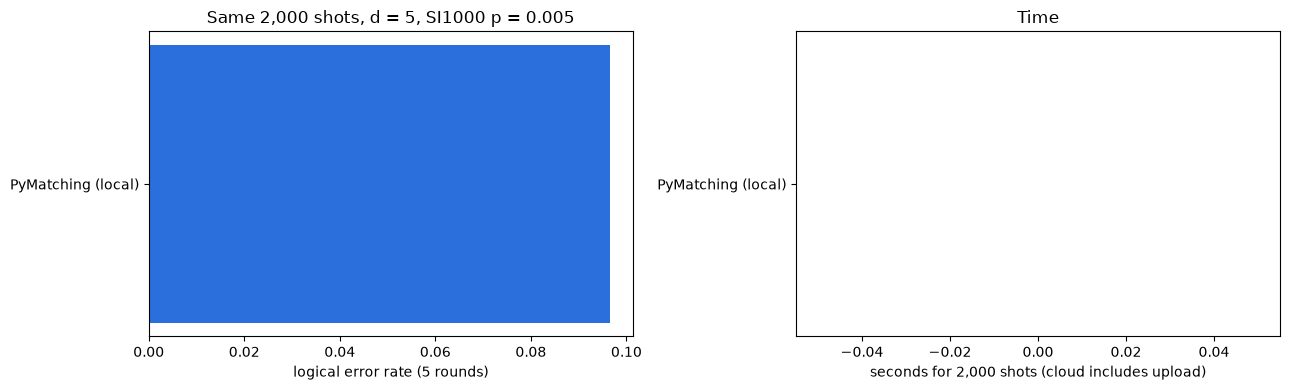

In [26]:
from deltakit.decode import MWPMDecoder, CCDecoder, BeliefMatchingDecoder, BPOSDecoder, ACDecoder
SP, SSHOTS = 0.005, 2000
dk5, _ = tour.dk_noisy(css_code_memory_circuit(RotatedPlanarCode(5, 5), 5, PauliBasis.Z), SI1000Noise(p=SP))
pm5, pm5_circ = PyMatchingDecoder.construct_decoder_and_stim_circuit(dk5)
st5 = stim.Circuit(str(pm5_circ))      # Z detectors only; every decoder gets this same circuit and shots
dets, obs = st5.compile_detector_sampler(seed=7).sample(SSHOTS, separate_observables=True)

MAKE = {
    "PyMatching (local)":     lambda: pm5,
    "MWPM (cloud)":           lambda: tour.cloud_decoder(MWPMDecoder, st5, cloud),
    "Collision Clustering (cloud)": lambda: tour.cloud_decoder(CCDecoder, st5, cloud),
    "Belief Matching (cloud)": lambda: tour.cloud_decoder(BeliefMatchingDecoder, st5, cloud),
    "BP-OSD (cloud)":         lambda: tour.cloud_decoder(BPOSDecoder, st5, cloud),
    "Ambiguity Clustering (cloud)": lambda: tour.cloud_decoder(ACDecoder, st5, cloud, bp_rounds=20),
}
def run_one(name, make):
    if "cloud" in name and cloud is None:
        return None
    t = time.time()
    try:
        pred = make().decode_batch_to_logical_flip(dets.astype(np.uint8))
    except Exception as e:
        print(name, "failed:", str(e)[:200]); return None
    return {"shots": SSHOTS, "failures": tour.count_failures(pred, obs), "seconds": round(time.time() - t, 1)}

rows = [r for name, make in MAKE.items()
        if (r := tour.cached_run("results/deltakit_decoders.csv",
                                 {"experiment": "surface d=5 SI1000", "p": SP, "decoder": name},
                                 lambda n=name, m=make: run_one(n, m)))]
res = pd.DataFrame(rows)
display(res)
if len(res):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    a1.barh(res.decoder, res.failures / res.shots, color="#2a6fdb"); a1.set_xlabel("logical error rate (5 rounds)")
    a2.barh(res.decoder, res.seconds, color="#e07a1f"); a2.set_xlabel("seconds for 2,000 shots (cloud includes upload)")
    a1.set_title("Same 2,000 shots, d = 5, SI1000 p = 0.005"); a2.set_title("Time")
    plt.tight_layout(); tour.savefig("deltakit_decoders_surface.png"); plt.show()

## Step 9 · Gross code: Deltakit's circuit vs IBM's, and cloud vs local decoders

Same noise model (IBM's uniform circuit noise, p = 0.004), 500 shots each.
1. **Locally**, with stabilizer-qec's BP-OSD (IBM's settings): IBM's circuit, stabilizer-qec's circuit and Deltakit's circuit.
2. **On the cloud** (needs the token): Deltakit's BP-OSD and Ambiguity Clustering on Deltakit's circuit.

[2026-11-21 21:30:53,985.985][deltakit-explorer][ERROR] decode: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" content="IE=Edge"><meta name="robots" content="noindex,nofollow"><meta name="viewport" content="width=device-width,initial-scale=1"><meta http-equiv="content-security-policy" content="default-src &#39;none&#39;; script-src &#39;nonce-E4HybFXaMuJUIZ5034ArI5&#39; &#39;unsafe-eval&#39; https://challenges.cloudflare.com; script-src-attr &#39;none&#39;; style-src &#39;unsafe-inline&#39;; img-src &#39;self&#39; https://challenges.cloudflare.com; connect-src &#39;self&#39; https://challenges.cloudflare.com; frame-src &#39;self&#39; https://challenges.cloudflare.com blob:; child-src &#39;self&#39; https://challenges.cloudflare.com blob:; worker-src blob:; form-action http: https:; base-uri &#39;self&#39;"><style>*{box-sizing:border-box;

BPOSDecoder failed: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" co


[2026-11-21 21:30:56,484.484][deltakit-explorer][ERROR] decode: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" content="IE=Edge"><meta name="robots" content="noindex,nofollow"><meta name="viewport" content="width=device-width,initial-scale=1"><meta http-equiv="content-security-policy" content="default-src &#39;none&#39;; script-src &#39;nonce-lf7CbGSZI23oKKfzUlYVm9&#39; &#39;unsafe-eval&#39; https://challenges.cloudflare.com; script-src-attr &#39;none&#39;; style-src &#39;unsafe-inline&#39;; img-src &#39;self&#39; https://challenges.cloudflare.com; connect-src &#39;self&#39; https://challenges.cloudflare.com; frame-src &#39;self&#39; https://challenges.cloudflare.com blob:; child-src &#39;self&#39; https://challenges.cloudflare.com blob:; worker-src blob:; form-action http: https:; base-uri &#39;self&#39;"><style>*{box-sizing:border-box;

ACDecoder failed: [403] Job not submitted: <!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" co


,experiment,p,decoder,shots,failures,seconds,P_L
0,gross IBM circuit uniform,0.004,"BP-OSD, stabilizer-qec (local)",500,17,15.4,0.034
1,gross stabilizer-qec circuit uniform,0.004,"BP-OSD, stabilizer-qec (local)",500,21,16.3,0.042
2,gross Deltakit circuit uniform,0.004,"BP-OSD, stabilizer-qec (local)",500,43,20.3,0.086


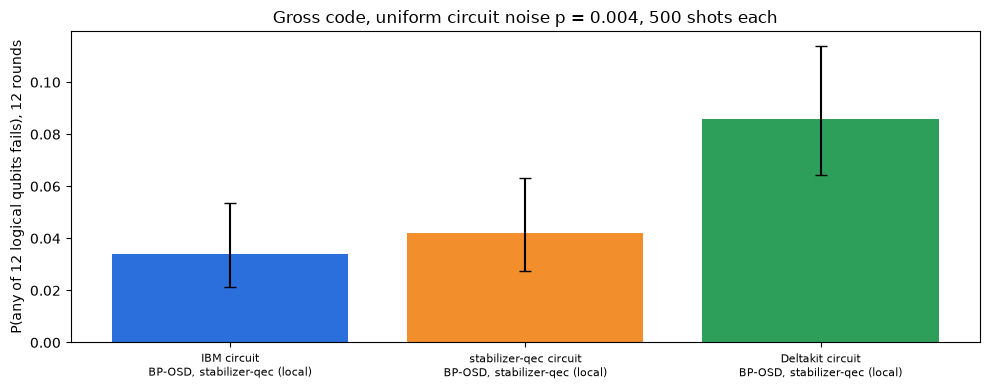

In [27]:
GSHOTS = 500
gd, go = dk_gross.compile_detector_sampler(seed=11).sample(GSHOTS, separate_observables=True)

def local_bposd(circ, d, o):
    t = time.time()
    dec = sq.BpOsd(circ.detector_error_model(decompose_errors=False), max_iter=80,
                   bp_method="minimum_sum", osd_method="osd_cs", osd_order=10)
    return {"shots": len(d), "failures": tour.count_failures(dec.decode_batch(d), o), "seconds": round(time.time() - t, 1)}

def cloud_run(cls, **params):
    if cloud is None:
        return None
    t = time.time()
    try:
        pred = tour.cloud_decoder(cls, dk_gross, cloud, **params).decode_batch_to_logical_flip(gd.astype(np.uint8))
    except Exception as e:
        print(cls.__name__, "failed:", str(e)[:200]); return None
    return {"shots": GSHOTS, "failures": tour.count_failures(pred, go), "seconds": round(time.time() - t, 1)}

id_, io = ibm_gross.compile_detector_sampler(seed=11).sample(GSHOTS, separate_observables=True)
sq_gross = stim.Circuit(str(sq.BivariateBicycleCode("gross").memory_circuit(12, GP)))   # stabilizer-qec's circuit, same noise
sd_, so_ = sq_gross.compile_detector_sampler(seed=11).sample(GSHOTS, separate_observables=True)
jobs = {
    ("IBM circuit", "BP-OSD, stabilizer-qec (local)"):      lambda: local_bposd(ibm_gross, id_, io),
    ("stabilizer-qec circuit", "BP-OSD, stabilizer-qec (local)"): lambda: local_bposd(sq_gross, sd_, so_),
    ("Deltakit circuit", "BP-OSD, stabilizer-qec (local)"): lambda: local_bposd(dk_gross, gd, go),
    ("Deltakit circuit", "BP-OSD (Deltakit cloud)"):        lambda: cloud_run(BPOSDecoder, max_bp_rounds=80, combination_sweep_order=10),
    ("Deltakit circuit", "Ambiguity Clustering (Deltakit cloud)"): lambda: cloud_run(ACDecoder, bp_rounds=80),
}
rows = [r for (circ, dec), job in jobs.items()
        if (r := tour.cached_run("results/deltakit_decoders.csv",
                                 {"experiment": f"gross {circ} uniform", "p": GP, "decoder": dec}, job))]
g = pd.DataFrame(rows)
g["P_L"] = g.failures / g.shots
display(g)
fig, ax = plt.subplots(figsize=(10, 4))
labels = [f"{e.replace('gross ', '').replace(' uniform', '')}\n{d}" for e, d in zip(g.experiment, g.decoder)]
ci = np.array([tour.wilson(f, n) for f, n in zip(g.failures, g.shots)])
ax.bar(labels, g.P_L, color=["#2a6fdb", "#f28e2b", "#2e9e5b", "#e07a1f", "#8a5cc2"][:len(g)])
ax.errorbar(range(len(g)), g.P_L, yerr=[g.P_L - ci[:, 0], ci[:, 1] - g.P_L], fmt="none", color="k", capsize=4)
ax.set_ylabel("P(any of 12 logical qubits fails), 12 rounds")
ax.set_title(f"Gross code, uniform circuit noise p = {GP}, {GSHOTS} shots each")
plt.xticks(fontsize=8); plt.tight_layout(); tour.savefig("deltakit_gross_decoders.png"); plt.show()

**What the graph shows.** With the same decoder and the same noise, IBM's and stabilizer-qec's circuits (both
Bravyi et al.'s depth-8 schedule) fail at similar rates, while Deltakit's gross circuit fails about 2–3× more
often, because its general schedule has about twice as many idle steps. The cloud bars
(when run with a token) show Deltakit's BP-OSD and AC on that same circuit.

## Step 10 · What we take from Deltakit

| From Deltakit | Where we use it |
|---|---|
| `BivariateBicycleCode` | a third, independent build of the gross code; check matrices identical to stabilizer-qec |
| `css_code_memory_circuit` | a general circuit builder for any CSS code — but not the optimised depth-8 gross code circuit |
| Noise models (ToyNoise, SI1000, SD6) | realistic noise options beyond uniform circuit noise |
| PyMatchingDecoder (local) | surface code decoding inside Deltakit |
| Cloud BP-OSD / AC / LC | decoders whose code is not public; usable only through Riverlane's server |

**Sources:** Deltakit docs https://deltakit-docs.riverlane.com (decoding guide, AC example) · Bravyi et al.,
*Nature* 627, 778 (2024) · Gidney, Newman, Fowler & Broughton, arXiv:2108.10457 (SI1000) · Higgott & Gidney,
arXiv:2303.15933 (PyMatching) · Higgott et al., arXiv:2203.04948 (belief matching) · Barber et al.,
arXiv:2309.05558 (Collision Clustering) · Roffe et al., arXiv:2005.07016 (BP-OSD) · Wolanski & Barber,
arXiv:2406.14527 (Ambiguity Clustering).